# Aula 9 – Associação e comparação entre abordagens de modelagem

## Versão do aluno — com apresentação visual dos resultados

### Objetivo da aula
Aplicar algoritmos de associação para identificar padrões frequentes em uma base industrial e comparar essa abordagem com classificação, regressão e agrupamento.

### Instruções
Complete as células indicadas ao longo da atividade e registre suas interpretações técnicas.  
Nesta versão, você também deverá **gerar gráficos** para visualizar os resultados.


## 1. Instalação e importação das bibliotecas

Importe as bibliotecas necessárias para:
- leitura da base;
- visualização com matplotlib;
- Apriori;
- FP-growth;
- geração de regras de associação.


In [ ]:
# Se necessário, descomente a linha abaixo
# !pip install mlxtend
! pip install mlxtend

import warnings
warnings.filterwarnings("ignore",category=DeprecationWarning)



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# Importe a biblioteca `pandas` utilizando o alias `pd` para manipulação e análise de tabelas e datasets.
# Importe a biblioteca `numpy` utilizando o alias `np` para realizar operações matemáticas e numéricas.
# Importe a biblioteca `matplotlib.pyplot` utilizando o alias `plt` para criação e exibição de gráficos.
# Importe as funções `apriori`, `fpgrowth` e `association_rules` do módulo `mlxtend.frequent_patterns` para realizar mineração de padrões frequentes e geração de regras de associação.
# Configure o pandas para exibir todas as colunas disponíveis do DataFrame durante a análise dos dados.

In [ ]:
# Complete aqui
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

pd.set_option("display.max_columns", None)



## 2. Leitura da base

Leia o arquivo `dados_aula9_associacao_industrial.csv` e exiba as primeiras linhas.


In [ ]:
# Utilize a função `read_csv()` da biblioteca pandas para carregar o arquivo CSV.
# Armazene os dados carregados na variável `df`.
# Utilize a função `head()` para visualizar as primeiras 5 linhas do DataFrame.

In [ ]:
# Complete aqui


df = pd.read_csv('/content/dados_aula9_associacao_industrial.csv')
df.head()

,id_registro,linha,turno,produto,alta_temperatura,alta_pressao,alta_vibracao,tempo_resposta_lento,erro_vazao_alto,leituras_invalidas_altas,valvula_desregulada,bomba_desgastada,consumo_energia_alto,manutencao_urgente
0,ASSOC_0001,Linha_B,Tarde,Base,Não,Sim,Sim,Sim,Não,Não,Não,Não,Sim,Não
1,ASSOC_0002,Linha_A,Manhã,Base,Não,Não,Sim,Não,Não,Não,Não,Sim,Sim,Sim
2,ASSOC_0003,Linha_A,Noite,Solvente,Sim,Não,Sim,Não,Não,Não,Não,Não,Sim,Não
3,ASSOC_0004,Linha_B,Manhã,Acido,Sim,Sim,Sim,Não,Não,Não,Não,Sim,Não,Não
4,ASSOC_0005,Linha_B,Tarde,Acido,Sim,Sim,Não,Não,Sim,Não,Não,Não,Não,Não


## 3. Inspeção inicial da base

Verifique:
- dimensão da base;
- tipos de dados;
- valores faltantes;
- duplicatas;
- valores únicos das colunas contextuais.

**Registro técnico:**
- Há inconsistências de grafia?
- Há duplicatas?
- O que deve ser ajustado antes de gerar regras?


In [ ]:
# Exiba na tela o texto "Dimensão da base:" e, na sequência, mostre a dimensão
# Utilize a função print() para exibir o texto "Dimensão da base:".
# Em seguida, utilize a propriedade .shape do DataFrame df para obter
# a quantidade de linhas e colunas da base.

# Utilize a função print() para exibir o texto "\nTipos de dados:".
# O \n deve ser utilizado para iniciar a mensagem em uma nova linha.

# Utilize a função print() e a propriedade .dtypes do DataFrame df
# para exibir o tipo de dado de cada coluna.

# Utilize a função print() para exibir o texto "\nValores faltantes:".

# Utilize o método .isna() do DataFrame df para identificar os valores nulos.
# Em seguida, utilize o método .sum() para contar a quantidade de valores
# nulos existente em cada coluna.
# Exiba o resultado utilizando a função print().

# Utilize a função print() para exibir o texto "\nDuplicatas:".
# Utilize o método .duplicated() do DataFrame df para identificar
# os registros duplicados.
# Em seguida, utilize o método .sum() para contar quantos registros duplicados existem.

# Crie um laço for utilizando a variável col para percorrer as colunas:
# 'linha', 'turno' e 'produto'.

# Dentro do laço, utilize a função print() para exibir o texto
# "\nValores únicos em" seguido do nome da coluna armazenado na variável col.

# Para acessar a coluna que está sendo analisada, utilize df[col].

# Utilize o método .dropna() para remover os valores nulos dessa coluna.

# Utilize o método .astype(str) para converter os valores da coluna para texto.

# Utilize o método .unique() para obter somente os valores diferentes existentes na coluna.

# Utilize a função sorted() para organizar os valores únicos em ordem crescente.

# Exiba o resultado utilizando a função print().

In [ ]:
# Complete aqui
print('Dimensão da base:', df.shape)
print('\nTipos de dados:')
print(df.dtypes)
print('\nValores faltantes:')
print(df.isnull().sum())
print('\nDuplicatas:', df.duplicated().sum())

for col in ['linha', 'turno', 'produto']:
    print(f'\nValores únicos em {col}:', sorted(df[col].dropna().astype(str).unique()))

Dimensão da base: (270, 14)

Tipos de dados:
id_registro                 object
linha                       object
turno                       object
produto                     object
alta_temperatura            object
alta_pressao                object
alta_vibracao               object
tempo_resposta_lento        object
erro_vazao_alto             object
leituras_invalidas_altas    object
valvula_desregulada         object
bomba_desgastada            object
consumo_energia_alto        object
manutencao_urgente          object
dtype: object

Valores faltantes:
id_registro                  0
linha                       10
turno                        0
produto                      0
alta_temperatura             0
alta_pressao                 0
alta_vibracao                0
tempo_resposta_lento         0
erro_vazao_alto              0
leituras_invalidas_altas     0
valvula_desregulada          0
bomba_desgastada             0
consumo_energia_alto         0
manutencao_urgente          

**Registro do aluno:**  
-  
-  
-  

## 4. Limpeza básica

Realize os ajustes necessários:
- remova duplicatas;
- preencha faltantes com a moda;
- padronize categorias com grafia inconsistente.


In [ ]:
# Utilize o método .drop_duplicates() do DataFrame df para remover
# registros duplicados.
# Utilize o método .copy() para criar uma cópia independente do DataFrame.

# Crie um laço for utilizando a variável col para percorrer as colunas:
# 'linha', 'turno' e 'produto'.

# Dentro do laço, utilize df[col] para acessar a coluna atual.

# Utilize o método .fillna() para substituir valores nulos.
# Como valor de preenchimento, utilize o método .mode()[0] da coluna atual
# para obter o valor mais frequente.

# Utilize o método .astype(str) para converter os valores da coluna para texto.

# Utilize o atributo .str e o método .strip() para remover espaços
# no início e no final dos textos.

# Na coluna 'produto', utilize o método .replace() para substituir
# o valor 'acido' por 'Acido'.

# Na coluna 'turno', utilize o método .replace() para substituir
# o valor 'noite' por 'Noite'.

# Utilize o método .head() para visualizar as primeiras 5 linhas do DataFrame.

In [ ]:
# Complete aqui
df = df.drop_duplicates().copy()

for col in ['linha', 'turno', 'produto']:
    df[col] = df[col].fillna(df[col].mode()[0]).astype(str).str.strip()

df['produto'] = df['produto'].replace({'acido': 'Acido'})
df['turno'] = df['turno'].replace({'noite': 'Noite'})

df.head()

,id_registro,linha,turno,produto,alta_temperatura,alta_pressao,alta_vibracao,tempo_resposta_lento,erro_vazao_alto,leituras_invalidas_altas,valvula_desregulada,bomba_desgastada,consumo_energia_alto,manutencao_urgente
0,ASSOC_0001,Linha_B,Tarde,Base,Não,Sim,Sim,Sim,Não,Não,Não,Não,Sim,Não
1,ASSOC_0002,Linha_A,Manhã,Base,Não,Não,Sim,Não,Não,Não,Não,Sim,Sim,Sim
2,ASSOC_0003,Linha_A,Noite,Solvente,Sim,Não,Sim,Não,Não,Não,Não,Não,Sim,Não
3,ASSOC_0004,Linha_B,Manhã,Acido,Sim,Sim,Sim,Não,Não,Não,Não,Sim,Não,Não
4,ASSOC_0005,Linha_B,Tarde,Acido,Sim,Sim,Não,Não,Sim,Não,Não,Não,Não,Não


## 5. Preparação da base para associação

Transforme as colunas binárias de **Sim/Não** para **1/0** e gere colunas dummies para `linha`, `turno` e `produto`.


In [ ]:
# Crie uma lista chamada colunas_binarias contendo os nomes:
# 'alta_temperatura', 'alta_pressao', 'alta_vibracao', 'tempo_resposta_lento',
# 'erro_vazao_alto', 'leituras_invalidas_altas', 'valvula_desregulada',
# 'bomba_desgastada', 'consumo_energia_alto' e 'manutencao_urgente'.

# Crie uma cópia do DataFrame df utilizando o método .copy()
# e armazene o resultado na variável df_bin.

# Crie um laço for utilizando a variável col para percorrer
# todas as colunas armazenadas em colunas_binarias.

# Dentro do laço, acesse cada coluna utilizando df_bin[col].

# Utilize o método .map() para transformar os valores:
# 'Sim' em 1 e 'Não' em 0.

# Utilize a função pd.get_dummies() para transformar as colunas
# 'linha', 'turno' e 'produto' em variáveis binárias (0 e 1).

# Acesse essas três colunas utilizando:
# df_bin[['linha', 'turno', 'produto']].

# Utilize o parâmetro prefix para definir os prefixos:
# 'linha', 'turno' e 'produto'.

# Armazene o resultado na variável df_contexto.

# Utilize a função pd.concat() para juntar:
# as colunas binárias de df_bin
# e as colunas de contexto de df_contexto.

# Utilize o parâmetro axis=1 para realizar a junção das colunas.

# Armazene o resultado na variável df_regras.

# Utilize o método .head() para visualizar as primeiras 5 linhas de df_regras.

In [ ]:
# Complete aqui
colunas_binarias = [
    'alta_temperatura', 'alta_pressao', 'alta_vibracao', 'tempo_resposta_lento',
    'erro_vazao_alto', 'leituras_invalidas_altas', 'valvula_desregulada',
    'bomba_desgastada', 'consumo_energia_alto', 'manutencao_urgente'
]

df_bin = df.copy()

for col in colunas_binarias:
    df_bin[col] = df_bin[col].map({'Sim': 1, 'Não': 0})

df_contexto = pd.get_dummies(
    df_bin[['linha', 'turno', 'produto']],
    prefix=['linha', 'turno', 'produto']
)

df_regras = pd.concat([df_bin[colunas_binarias], df_contexto], axis=1)
df_regras.head()

,alta_temperatura,alta_pressao,alta_vibracao,tempo_resposta_lento,erro_vazao_alto,leituras_invalidas_altas,valvula_desregulada,bomba_desgastada,consumo_energia_alto,manutencao_urgente,linha_Linha_A,linha_Linha_B,linha_Linha_C,turno_Manhã,turno_Noite,turno_Tarde,produto_Acido,produto_Base,produto_Solvente
0,0,1,1,1,0,0,0,0,1,0,False,True,False,False,False,True,False,True,False
1,0,0,1,0,0,0,0,1,1,1,True,False,False,True,False,False,False,True,False
2,1,0,1,0,0,0,0,0,1,0,True,False,False,False,True,False,False,False,True
3,1,1,1,0,0,0,0,1,0,0,False,True,False,True,False,False,True,False,False
4,1,1,0,0,1,0,0,0,0,0,False,True,False,False,False,True,True,False,False


## 6. Visualização inicial dos itens mais frequentes

Calcule a frequência relativa dos itens e faça um gráfico com os 10 itens mais frequentes.


In [ ]:
# Calcule a média de cada coluna do DataFrame df_regras
# utilizando o método .mean().

# Utilize o método .sort_values() para ordenar os resultados.
# Utilize o parâmetro ascending=False para ordenar do maior
# para o menor valor.

# Armazene o resultado na variável frequencia_itens.

# Utilize o método .head(10) para exibir os 10 itens
# com maior frequência.

In [ ]:
# Complete aqui
frequencia_itens = df_regras.mean().sort_values(ascending=False)
frequencia_itens.head(10)

,0
consumo_energia_alto,0.469231
alta_pressao,0.450000
alta_temperatura,0.430769
linha_Linha_B,0.411538
alta_vibracao,0.376923
linha_Linha_A,0.369231
turno_Manhã,0.365385
produto_Base,0.353846
produto_Acido,0.342308
turno_Tarde,0.338462


In [ ]:
# Utilize o método .head(10) de frequencia_itens
# para obter os 10 itens mais frequentes.
# Armazene o resultado na variável top_itens.

# Utilize plt.figure() para criar a área do gráfico.
# Utilize figsize=(10, 5) para definir largura e altura.

# Utilize plt.bar() para criar um gráfico de barras.
# Utilize top_itens.index para definir os nomes dos itens.
# Utilize top_itens.values para definir os valores das barras.

# Utilize plt.title() para definir o título:
# 'Top 10 itens mais frequentes na base'.

# Utilize plt.xlabel() para definir o rótulo do eixo X como 'Itens'.

# Utilize plt.ylabel() para definir o rótulo do eixo Y
# como 'Frequência relativa'.

# Utilize plt.xticks() com rotation=75 para girar os nomes dos itens.

# Utilize plt.tight_layout() para ajustar o espaço do gráfico.

# Utilize plt.show() para exibir o gráfico.

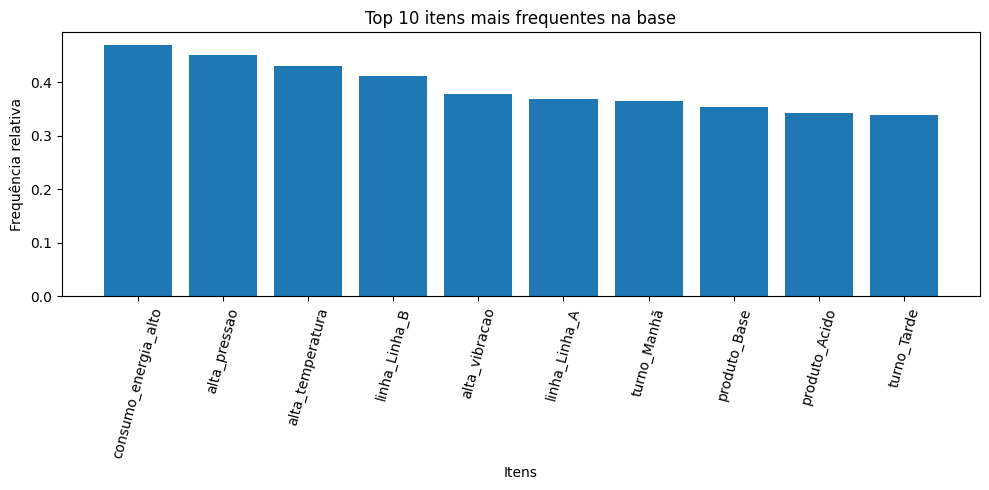

In [ ]:
# Gere o gráfico aqui
top_itens = frequencia_itens.head(10)

plt.figure(figsize=(10, 5))
plt.bar(top_itens.index,top_itens.values)
plt.title('Top 10 itens mais frequentes na base')
plt.xlabel('Itens')
plt.ylabel('Frequência relativa')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

## 7. Conceitos fundamentais

Explique, com suas palavras:
- o que é **suporte**;
- o que é **confiança**;
- o que significa **lift** maior que 1.


**Resposta do aluno:**  
- Suporte:  
- Confiança:  
- Lift > 1:  


## 8. Geração de itemsets frequentes com Apriori

Aplique o algoritmo Apriori com suporte mínimo de 0,08.


###***Pergunta de Negócio***

>Quais problemas e condições operacionais costumam acontecer juntos? <br/>
Ou  <br/>
>Quais combinações de condições operacionais podem indicar padrões recorrentes de problemas na indústria?

In [ ]:
# Utilize a função apriori() para identificar conjuntos de itens frequentes
# no DataFrame df_regras.

# Utilize o parâmetro min_support=0.08 para considerar
# apenas os conjuntos com suporte mínimo de 8%.

# Utilize o parâmetro use_colnames=True para utilizar
# os nomes das colunas nos conjuntos encontrados.

# Armazene o resultado na variável itemsets_apriori.

# Utilize o método .sort_values() para ordenar os resultados
# pela coluna 'support'.

# Utilize o parâmetro ascending=False para ordenar
# do maior suporte para o menor.

# Utilize o método .head(15) para exibir os 15 primeiros
# conjuntos de itens mais frequentes.

In [ ]:
# Complete aqui
itemsets_apriori = apriori(df_regras, min_support=0.08, use_colnames=True)
itemsets_apriori = itemsets_apriori.sort_values(by='support', ascending=False)
itemsets_apriori.head(15)

,support,itemsets
8,0.469231,(consumo_energia_alto)
1,0.45,(alta_pressao)
0,0.430769,(alta_temperatura)
11,0.411538,(linha_Linha_B)
2,0.376923,(alta_vibracao)
10,0.369231,(linha_Linha_A)
13,0.365385,(turno_Manhã)
17,0.353846,(produto_Base)
16,0.342308,(produto_Acido)
15,0.338462,(turno_Tarde)


>O Apriori encontrou 193 combinações de itens que aparecem em pelo menos 21 dos 260 registros da base.

## 9. Visualização dos itemsets mais frequentes

Crie uma coluna em formato de texto para os itemsets e faça um gráfico com os 10 itemsets de maior suporte.


In [ ]:
# Utilize o método .head(10) de itemsets_apriori para selecionar
# os 10 primeiros itemsets.
# Utilize o método .copy() para criar uma cópia.
# Armazene o resultado em top_itemsets_apriori.

# Crie uma nova coluna chamada 'itemset_str'.

# Utilize o método .apply() na coluna 'itemsets' para processar
# cada conjunto de itens.

# Dentro do apply(), utilize sorted() para ordenar os itens.

# Utilize list() para transformar o conjunto de itens em uma lista.

# Utilize o método .join() para juntar os itens usando ', ' como separador.

# Utilize uma função lambda para aplicar essa transformação em cada itemset.

# Utilize df[['itemset_str', 'support']] para selecionar somente
# as colunas 'itemset_str' e 'support' e exibir o resultado.

In [ ]:
# Complete aqui
top_itemsets_apriori = itemsets_apriori.head(10).copy()
top_itemsets_apriori['itemset_str'] = top_itemsets_apriori['itemsets'].apply(
    lambda x: ', '.join(sorted(list(x)))
)
top_itemsets_apriori[['itemset_str', 'support']]

,itemset_str,support
8,consumo_energia_alto,0.469231
1,alta_pressao,0.45
0,alta_temperatura,0.430769
11,linha_Linha_B,0.411538
2,alta_vibracao,0.376923
10,linha_Linha_A,0.369231
13,turno_Manhã,0.365385
17,produto_Base,0.353846
16,produto_Acido,0.342308
15,turno_Tarde,0.338462


In [ ]:
# Utilize a função plt.figure() para criar a área do gráfico.
# Utilize o parâmetro figsize=(10, 5) para definir o tamanho da figura.

# Utilize a função plt.bar() para criar um gráfico de barras.
# Utilize a coluna 'itemset_str' de top_itemsets_apriori no eixo X.
# Utilize a coluna 'support' de top_itemsets_apriori no eixo Y.

# Utilize a função plt.title() para definir o título:
# 'Top 10 itemsets mais frequentes - Apriori'.

# Utilize a função plt.xlabel() para definir o nome do eixo X:
# 'Itemsets'.

# Utilize a função plt.ylabel() para definir o nome do eixo Y:
# 'Suporte'.

# Utilize a função plt.xticks() com o parâmetro rotation=75
# para rotacionar os nomes dos itemsets em 75 graus.

# Utilize a função plt.tight_layout() para ajustar automaticamente
# o espaçamento dos elementos do gráfico.

# Utilize a função plt.show() para exibir o gráfico.

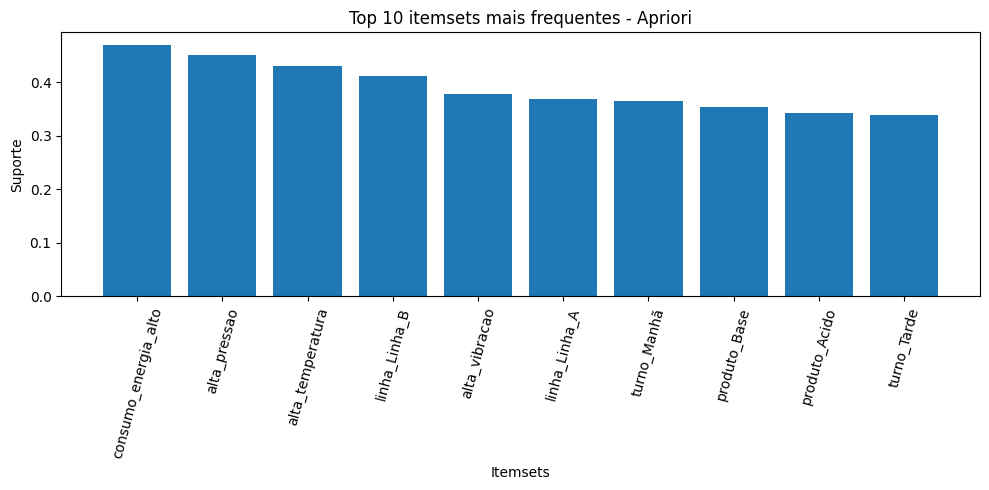

In [ ]:
# Gere o gráfico aqui
plt.figure(figsize=(10, 5))
plt.bar(top_itemsets_apriori['itemset_str'], top_itemsets_apriori['support'])
plt.title('Top 10 itemsets mais frequentes - Apriori')
plt.xlabel('Itemsets')
plt.ylabel('Suporte')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

## 10. Geração das regras de associação com Apriori

Gere regras usando confiança mínima de 0,6 e exiba as principais.


In [ ]:
# Utilize a função association_rules() para gerar regras de associação
# a partir dos itemsets armazenados em itemsets_apriori.

# Utilize o parâmetro metric='confidence' para utilizar a confiança
# como métrica para selecionar as regras.

# Utilize o parâmetro min_threshold=0.6 para considerar apenas regras
# com confiança mínima de 60%.

# Armazene o resultado na variável regras_apriori.

# Utilize o método .sort_values() para ordenar as regras.
# Utilize by=['lift', 'confidence'] para ordenar primeiro pelo lift
# e depois pela confidence.

# Utilize ascending=False para ordenar os valores do maior para o menor.

# Selecione as colunas 'antecedents', 'consequents', 'support',
# 'confidence' e 'lift'.

# Utilize o método .head(15) para exibir as 15 primeiras regras.

In [ ]:
# Complete aqui
regras_apriori = association_rules(
    itemsets_apriori,
    metric='confidence',
    min_threshold=0.6
)

regras_apriori = regras_apriori.sort_values(
    by=['lift', 'confidence'],
    ascending=False
)

### ***Explicando:***

`antecedents` e `consequents` não estão sendo aplicados ao algoritmo.

>Eles são colunas que a função association_rules() cria no resultado.

* ***antecedents*** → de onde parte a regra
* ***consequents*** → para onde aponta
* ***support*** → frequência da combinação
* ***confidence*** → frequência do consequente quando o antecedente acontece
* ***lift*** → força da associação em relação à ocorrência esperada

>Isso cria uma sequencia:         <br/>
`Apriori`                        <br/>
   `↓`                           <br/>
`Encontra itemsets frequentes`   <br/>
   `↓`                           <br/>
`support`                        <br/>
   `↓`                           <br/>
`Transforma itemsets em regras`  <br/>
   `↓`                           <br/>
`antecedents → consequents`      <br/>
   `↓`                           <br/>
`calcula confidence e lift`      <br/>



## 11. Visualização das principais regras do Apriori

Monte uma coluna de texto com as regras e faça:
- um gráfico das principais regras por **lift**;
- um gráfico das principais regras por **confiança**.


In [ ]:
# Selecione as colunas 'antecedents', 'consequents', 'support',
# 'confidence' e 'lift' do DataFrame regras_apriori.
# Utilize o método .head(10) para selecionar as 10 primeiras regras.
# Utilize o método .copy() para criar uma cópia.
# Armazene o resultado na variável top_regras_apriori.

# Crie uma nova coluna chamada 'regra'.

# Utilize o método .apply() para processar cada linha do DataFrame.

# Utilize uma função lambda com a variável row para acessar os valores
# de cada linha.

# Acesse row['antecedents'] para obter os itens que formam o antecedente.

# Utilize a função list() para transformar os itens em uma lista.

# Utilize a função sorted() para ordenar os itens.

# Utilize o método .join() para juntar os itens usando ', ' como separador.

# Utilize ' -> ' para separar o antecedente do consequente.

# Acesse row['consequents'] para obter os itens que formam o consequente.

# Utilize novamente list(), sorted() e .join() para organizar os itens.

# Utilize uma f-string para montar a regra no formato:
# 'antecedente -> consequente'.

# Utilize o parâmetro axis=1 no método .apply()
# para aplicar a função em cada linha.

# Selecione as colunas 'regra', 'support', 'confidence' e 'lift'.

# Exiba o resultado.

In [ ]:
top_regras_apriori = regras_apriori[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10).copy()
top_regras_apriori['regra'] = top_regras_apriori.apply(
    lambda row: f"{', '.join(sorted(list(row['antecedents'])))} -> {', '.join(sorted(list(row['consequents'])))}",
    axis=1
)

top_regras_apriori[['regra', 'support', 'confidence', 'lift']]

,regra,support,confidence,lift
65,"alta_temperatura, valvula_desregulada -> erro_...",0.088462,0.696970,3.020202
41,"alta_pressao, valvula_desregulada -> erro_vaza...",0.092308,0.648649,2.810811
56,"alta_vibracao, leituras_invalidas_altas -> tem...",0.088462,0.741935,2.606800
39,"alta_pressao, erro_vazao_alto -> valvula_desre...",0.092308,0.705882,2.584921
30,"bomba_desgastada, tempo_resposta_lento -> alta...",0.100000,0.962963,2.554800
63,"bomba_desgastada, produto_Base -> alta_vibracao",0.088462,0.958333,2.542517
47,"alta_pressao, leituras_invalidas_altas -> temp...",0.092308,0.705882,2.480127
46,"alta_pressao, tempo_resposta_lento -> leituras...",0.092308,0.615385,2.461538
20,"alta_pressao, alta_vibracao -> bomba_desgastada",0.115385,0.652174,2.457467
13,"alta_vibracao, consumo_energia_alto -> bomba_d...",0.142308,0.649123,2.445970


###***Explicando Confiança:***

***Confiança = A + B(consequente) / A(antecedente) = Divide a consequencia sobre a antecedencia***

> Ela mede quantas vezes o consequente aparece quando o antecedente aparece. <br/>

***EX:***

***Antecedente:*** <br/>
`alta_temperatura + valvula_desregulada → 33 registros` <br/><br/>

***Antecedente + consequente:*** <br/>
`alta_temperatura + valvula_desregulada + erro_vazao_alto → 23 registros`

***Então:***

Confiança = 23 ÷ 33 = 69,7% <br/><br/>

>Portanto:<br/>
Quando `alta_temperatura + valvula_desregulada` acontecem, `erro_vazao_alto` também acontece em 69,7% dos casos.<br/>
A confiança mede a proporção do antecedente que também contém o consequente.

## ***Explicando Lift:***

***Lift = confiança da regra ÷ frequência normal do consequente***

> ***EX:...***    `alta_temperatura + valvula_desregulada → erro_vazao_alto`<br/>
* Quando temos alta temperatura + válvula desregulada, o erro_vazao_alto acontece em 69,7% dos casos.(Confiança/Confidence)
* “Esse 69,7% é muito maior do que a frequência normal de erro_vazao_alto?”

***SIM***
> Na base inteira, `erro_vazao_alto` aparece em aproximadamente 23% dos registros. `(N Registros/N Registros DataSet)` <br/>
No nosso exomplo `erro_vazao_alto` ocorre normalmente em aproximadamente 23% da base, 60 linhas das 260 linhas do DataSet.

***Então***
> 69,7% ÷ 23% ≈ 3,02 <br/>

*O erro de vazão aparece 3,02 vezes mais frequentemente quando temos alta_temperatura + valvula_desregulada do que na base normalmente. </br></br></br>


***OBSERVAÇÃO***:
>Frequência normal:
* De todos os 260 registros, 23,08% têm erro de vazão alto.<br/>

>Confiança:
* Entre os registros que têm alta temperatura + válvula desregulada, 69,7% também têm erro de vazão alto.

> O `erro_vazao_alto` ocorre proporcionalmente muito mais dentro do grupo `alta_temperatura + valvula_desregulada` do que na população geral da base.

In [ ]:
# Utilize a função plt.figure() para criar a área do gráfico.
# Utilize o parâmetro figsize=(10, 5) para definir o tamanho da figura.

# Utilize a função plt.bar() para criar um gráfico de barras.
# Utilize a coluna 'regra' de top_regras_apriori para definir
# os valores do eixo X.
# Utilize a coluna 'lift' de top_regras_apriori para definir
# a altura das barras no eixo Y.

# Utilize a função plt.title() para definir o título:
# 'Top 10 regras do Apriori por lift'.

# Utilize a função plt.xlabel() para definir o nome do eixo X:
# 'Regras'.

# Utilize a função plt.ylabel() para definir o nome do eixo Y:
# 'Lift'.

# Utilize a função plt.xticks() com o parâmetro rotation=75
# para rotacionar os nomes das regras em 75 graus.

# Utilize a função plt.tight_layout() para ajustar o espaçamento
# dos elementos do gráfico.

# Utilize a função plt.show() para exibir o gráfico.

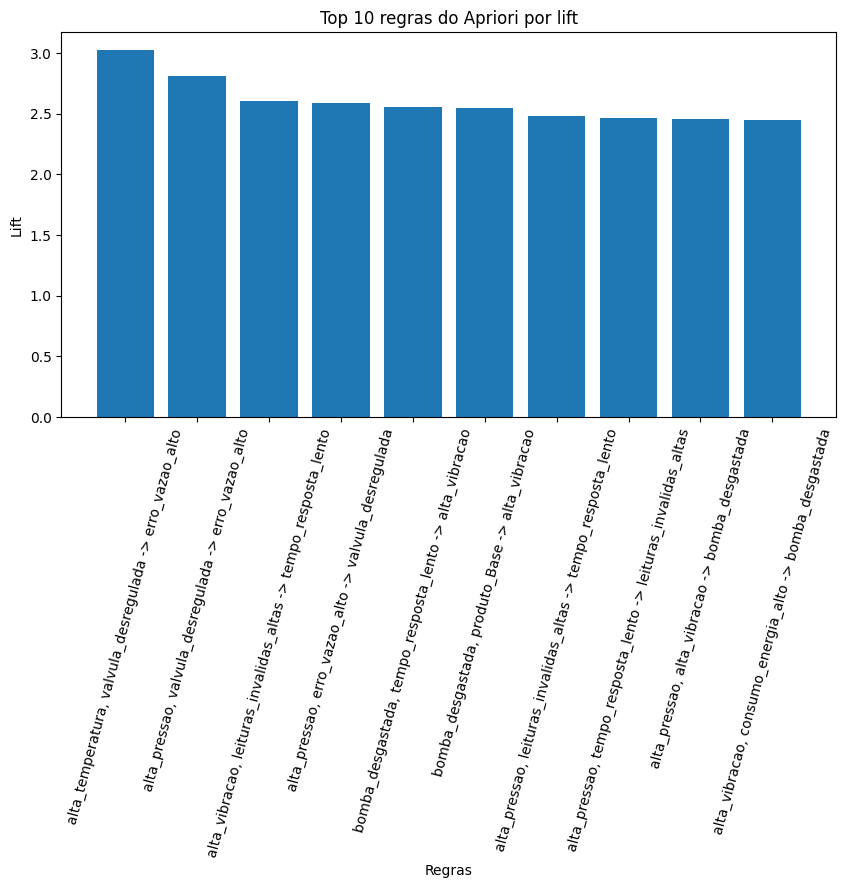

In [ ]:
plt.figure(figsize=(10, 5))
plt.bar(top_regras_apriori['regra'], top_regras_apriori['lift'])
plt.title('Top 10 regras do Apriori por lift')
plt.xlabel('Regras')
plt.ylabel('Lift')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [ ]:
# Utilize a função plt.figure() para criar a área do gráfico.
# Utilize o parâmetro figsize=(10, 5) para definir o tamanho da figura.

# Utilize a função plt.bar() para criar um gráfico de barras.
# Utilize a coluna 'regra' de top_regras_apriori para definir
# os valores do eixo X.
# Utilize a coluna 'confidence' de top_regras_apriori para definir
# a altura das barras no eixo Y.

# Utilize a função plt.title() para definir o título:
# 'Top 10 regras do Apriori por confiança'.

# Utilize a função plt.xlabel() para definir o nome do eixo X:
# 'Regras'.

# Utilize a função plt.ylabel() para definir o nome do eixo Y:
# 'Confiança'.

# Utilize a função plt.xticks() com o parâmetro rotation=75
# para rotacionar os nomes das regras em 75 graus.

# Utilize a função plt.tight_layout() para ajustar o espaçamento
# dos elementos do gráfico.

# Utilize a função plt.show() para exibir o gráfico.

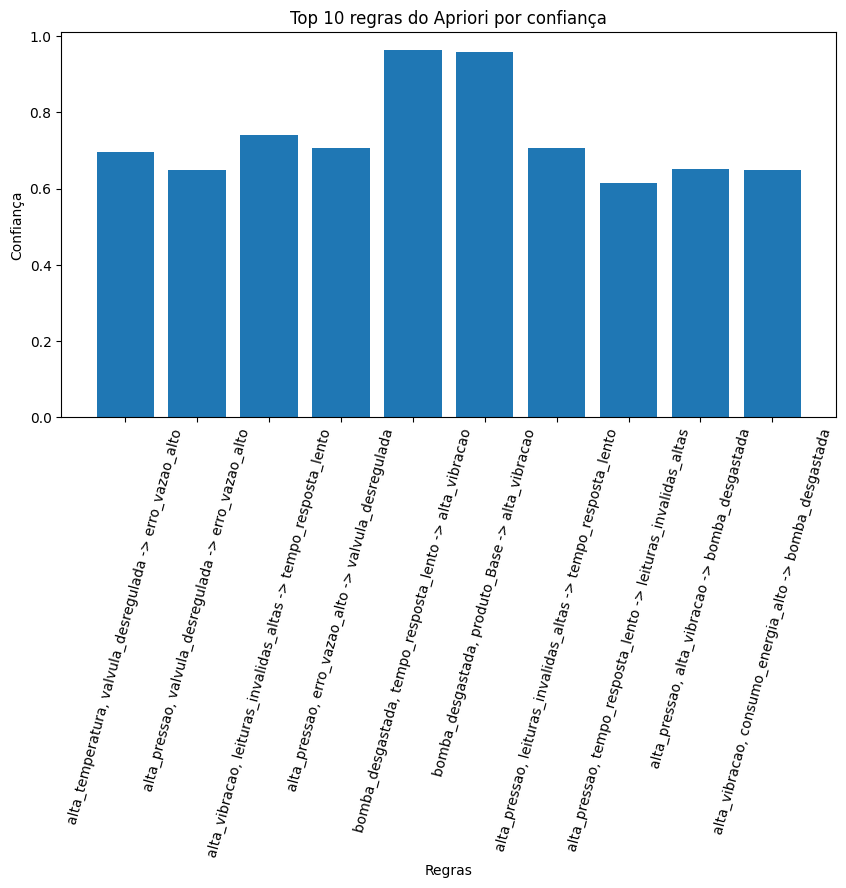

In [ ]:
plt.figure(figsize=(10, 5))
plt.bar(top_regras_apriori['regra'], top_regras_apriori['confidence'])
plt.title('Top 10 regras do Apriori por confiança')
plt.xlabel('Regras')
plt.ylabel('Confiança')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

## 12. Geração de itemsets e regras com FP-growth

Repita o processo com FP-growth.


In [ ]:
# Encontre os conjuntos de itens frequentes utilizando a função `fpgrowth()`.
# Utilize `df_regras` como base de dados.
# Defina `min_support=0.08` para considerar padrões presentes em pelo menos 8% dos registros.
# Utilize `use_colnames=True` para retornar os nomes das colunas nos conjuntos encontrados.

# Ordene os conjuntos de itens pela coluna `support` utilizando o método `sort_values()`.
# Utilize `ascending=False` para apresentar os maiores valores de suporte primeiro.

# Gere as regras de associação utilizando a função `association_rules()`.
# Utilize os itemsets encontrados pelo FP-Growth como primeiro argumento.
# Defina `metric='confidence'` para utilizar a confiança como métrica.
# Defina `min_threshold=0.6` para considerar somente regras com confiança mínima de 60%.

# Ordene as regras utilizando as colunas `lift` e `confidence`.
# Utilize `ascending=False` para apresentar primeiro os maiores valores dessas métricas.

# Selecione as colunas `antecedents`, `consequents`, `support`, `confidence` e `lift`.
# Utilize o método `head(15)` para visualizar as 15 primeiras regras.

In [ ]:
itemsets_fpgrowth = fpgrowth(df_regras, min_support=0.08, use_colnames=True)
itemsets_fpgrowth = itemsets_fpgrowth.sort_values(by='support', ascending=False)

regras_fpgrowth = association_rules(itemsets_fpgrowth, metric='confidence', min_threshold=0.6)
regras_fpgrowth = regras_fpgrowth.sort_values(by=['lift', 'confidence'], ascending=False)

regras_fpgrowth[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(15)

,antecedents,consequents,support,confidence,lift
60,"(alta_temperatura, valvula_desregulada)",(erro_vazao_alto),0.088462,0.696970,3.020202
53,"(alta_pressao, valvula_desregulada)",(erro_vazao_alto),0.092308,0.648649,2.810811
61,"(alta_vibracao, leituras_invalidas_altas)",(tempo_resposta_lento),0.088462,0.741935,2.606800
51,"(erro_vazao_alto, alta_pressao)",(valvula_desregulada),0.092308,0.705882,2.584921
30,"(bomba_desgastada, tempo_resposta_lento)",(alta_vibracao),0.100000,0.962963,2.554800
56,"(bomba_desgastada, produto_Base)",(alta_vibracao),0.088462,0.958333,2.542517
47,"(alta_pressao, leituras_invalidas_altas)",(tempo_resposta_lento),0.092308,0.705882,2.480127
46,"(alta_pressao, tempo_resposta_lento)",(leituras_invalidas_altas),0.092308,0.615385,2.461538
21,"(alta_vibracao, alta_pressao)",(bomba_desgastada),0.115385,0.652174,2.457467
14,"(alta_vibracao, consumo_energia_alto)",(bomba_desgastada),0.142308,0.649123,2.445970


## 13. Visualização das principais regras do FP-growth

Crie uma visualização das principais regras por lift.


In [ ]:
# Crie a variável `top_regras_fpgrowth` para armazenar as 10 principais regras.
# Utilize a variável `regras_fpgrowth` como fonte dos dados.
# Selecione as colunas `antecedents`, `consequents`, `support`, `confidence` e `lift`.
# Utilize o método `head(10)` para selecionar somente as 10 primeiras regras.
# Utilize o método `copy()` para criar uma cópia desses dados.

# Crie uma nova coluna chamada `regra` dentro da variável `top_regras_fpgrowth`.
# Utilize o método `apply()` para executar uma transformação em cada linha da tabela.
# Utilize `lambda row` para representar a linha que está sendo analisada.
# Acesse `row['antecedents']` para obter os itens do antecedente da regra.
# Utilize `list()` para transformar os itens do antecedente em uma lista.
# Utilize `sorted()` para ordenar os itens.
# Utilize `join()` para juntar os itens em um único texto, separados por vírgula.
# Utilize uma f-string para montar o texto da regra.
# Utilize `->` para separar visualmente o antecedente do consequente.
# Repita o mesmo processo para `row['consequents']`.
# Utilize `axis=1` para informar que o `apply()` deve executar a função linha por linha.

# Exiba na tela somente as colunas `regra`, `support`, `confidence` e `lift`.
# Utilize a variável `top_regras_fpgrowth` para realizar essa seleção.
# A coluna `regra` apresenta o antecedente e o consequente no formato "A -> B".
# A coluna `support` apresenta a frequência da regra na base de dados.
# A coluna `confidence` apresenta a confiança da regra.
# A coluna `lift` apresenta a força da associação.

In [ ]:
top_regras_fpgrowth = regras_fpgrowth[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10).copy()
top_regras_fpgrowth['regra'] = top_regras_fpgrowth.apply(
    lambda row: f"{', '.join(sorted(list(row['antecedents'])))} -> {', '.join(sorted(list(row['consequents'])))}",
    axis=1
)

top_regras_fpgrowth[['regra', 'support', 'confidence', 'lift']]

,regra,support,confidence,lift
60,"alta_temperatura, valvula_desregulada -> erro_...",0.088462,0.696970,3.020202
53,"alta_pressao, valvula_desregulada -> erro_vaza...",0.092308,0.648649,2.810811
61,"alta_vibracao, leituras_invalidas_altas -> tem...",0.088462,0.741935,2.606800
51,"alta_pressao, erro_vazao_alto -> valvula_desre...",0.092308,0.705882,2.584921
30,"bomba_desgastada, tempo_resposta_lento -> alta...",0.100000,0.962963,2.554800
56,"bomba_desgastada, produto_Base -> alta_vibracao",0.088462,0.958333,2.542517
47,"alta_pressao, leituras_invalidas_altas -> temp...",0.092308,0.705882,2.480127
46,"alta_pressao, tempo_resposta_lento -> leituras...",0.092308,0.615385,2.461538
21,"alta_pressao, alta_vibracao -> bomba_desgastada",0.115385,0.652174,2.457467
14,"alta_vibracao, consumo_energia_alto -> bomba_d...",0.142308,0.649123,2.445970


In [ ]:
# Crie uma figura utilizando `plt.figure()`.
# Defina o tamanho da figura com `figsize=(10, 5)`,
# sendo 10 para a largura e 5 para a altura.

# Crie um gráfico de barras utilizando `plt.bar()`.
# No eixo X, utilize a coluna `regra` da variável `top_regras_fpgrowth`.
# No eixo Y, utilize a coluna `lift` da variável `top_regras_fpgrowth`.

# Defina o título do gráfico utilizando `plt.title()`.
# O título deve ser: "Top 10 regras do FP-growth por lift".

# Defina o nome do eixo X utilizando `plt.xlabel()`.
# O nome do eixo X deve ser: "Regras".

# Defina o nome do eixo Y utilizando `plt.ylabel()`.
# O nome do eixo Y deve ser: "Lift".

# Utilize `plt.xticks()` para alterar a rotação dos textos do eixo X.
# Defina `rotation=75` para girar os nomes das regras em 75 graus.

# Utilize `plt.tight_layout()` para ajustar automaticamente o espaço do gráfico
# e evitar que os nomes das regras fiquem cortados.

# Utilize `plt.show()` para exibir o gráfico na tela.

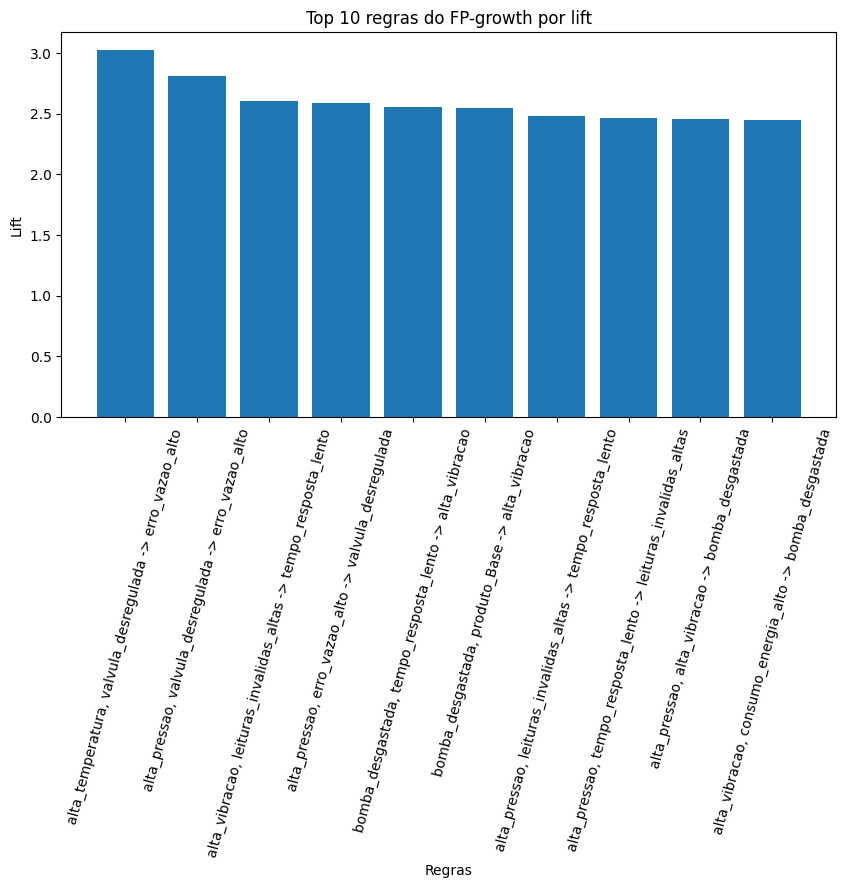

In [ ]:
plt.figure(figsize=(10, 5))
plt.bar(top_regras_fpgrowth['regra'], top_regras_fpgrowth['lift'])
plt.title('Top 10 regras do FP-growth por lift')
plt.xlabel('Regras')
plt.ylabel('Lift')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


#***Apriori x FP_Growth***


| Característica | Apriori | FP-Growth |
|---|---|---|
| **Como funciona** | Gera candidatos e testa | Constrói uma estrutura chamada FP-Tree |
| **Velocidade** | Geralmente mais lento em bases grandes | Geralmente mais rápido |
| **Memória** | Pode gerar muitos candidatos | Evita gerar muitos candidatos |
| **Facilidade de entender** | Mais simples | Um pouco mais complexo |
| **Estratégia** | 1 item → 2 itens → 3 itens | Explora os padrões diretamente na FP-Tree |
| **Principal vantagem** | Fácil de entender e implementar | Mais eficiente em grandes conjuntos de dados |

<br/>
<br/>

>Apriori = gera e testa combinações. <br/>
>FP-Growth = organiza os dados em uma árvore e encontra os padrões de forma mais eficiente.

## 14. Comparação visual entre Apriori e FP-growth

Monte uma tabela comparando:
- quantidade de itemsets;
- quantidade de regras.

Depois, faça dois gráficos de barras.


In [ ]:
# Crie a variável `comparacao_algoritmos` para armazenar uma tabela
# comparando os resultados dos algoritmos Apriori e FP-Growth.

# Utilize `pd.DataFrame()` para criar um novo DataFrame.

# Crie a coluna `Algoritmo` para informar o nome de cada algoritmo analisado.
# Informe os valores `Apriori` e `FP-growth`.

# Crie a coluna `Quantidade_itemsets` para armazenar a quantidade
# de conjuntos de itens encontrados por cada algoritmo.
# Utilize `len()` para contar quantos itemsets existem em `itemsets_apriori`
# e em `itemsets_fpgrowth`.

# Crie a coluna `Quantidade_regras` para armazenar a quantidade
# de regras de associação geradas por cada algoritmo.
# Utilize `len()` para contar quantas regras existem em `regras_apriori`
# e em `regras_fpgrowth`.

# Depois de criar o DataFrame, informe `comparacao_algoritmos`
# para visualizar a tabela de comparação.

In [ ]:
comparacao_algoritmos = pd.DataFrame({
    'Algoritmo': ['Apriori', 'FP-growth'],
    'Quantidade_itemsets': [len(itemsets_apriori), len(itemsets_fpgrowth)],
    'Quantidade_regras': [len(regras_apriori), len(regras_fpgrowth)]
})

comparacao_algoritmos

,Algoritmo,Quantidade_itemsets,Quantidade_regras
0,Apriori,193,82
1,FP-growth,193,82


In [ ]:
# Crie uma nova figura utilizando `plt.figure()`.
# Defina o tamanho da figura com `figsize=(8, 5)`,
# sendo 8 para a largura e 5 para a altura.

# Crie um gráfico de barras utilizando `plt.bar()`.
# No eixo X, utilize a coluna `Algoritmo` da variável `comparacao_algoritmos`.
# No eixo Y, utilize a coluna `Quantidade_itemsets` da variável `comparacao_algoritmos`.
# Dessa forma, o gráfico mostrará a quantidade de itemsets encontrada por cada algoritmo.

# Defina o título do gráfico utilizando `plt.title()`.
# O título deve ser: "Comparação da quantidade de itemsets".

# Defina o nome do eixo X utilizando `plt.xlabel()`.
# O nome do eixo X deve ser: "Algoritmo".

# Defina o nome do eixo Y utilizando `plt.ylabel()`.
# O nome do eixo Y deve ser: "Quantidade de itemsets".

# Utilize `plt.tight_layout()` para ajustar automaticamente o espaço
# entre os elementos do gráfico.

# Utilize `plt.show()` para exibir o gráfico na tela.

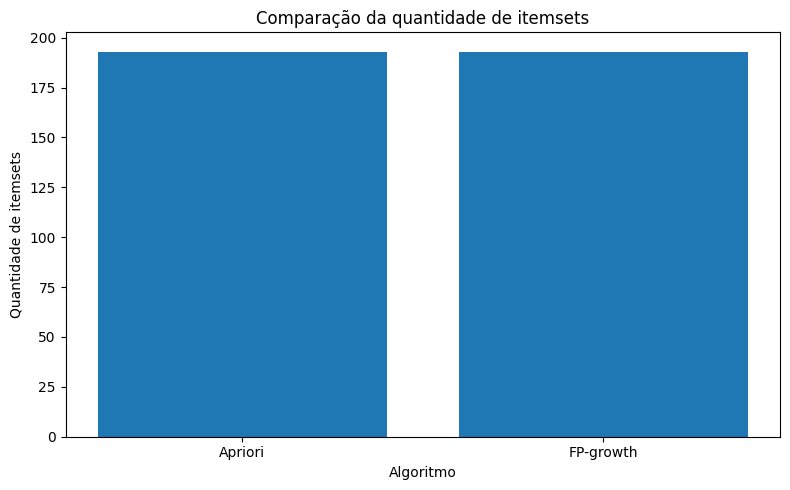

In [ ]:
plt.figure(figsize=(8, 5))
plt.bar(comparacao_algoritmos['Algoritmo'], comparacao_algoritmos['Quantidade_itemsets'])
plt.title('Comparação da quantidade de itemsets')
plt.xlabel('Algoritmo')
plt.ylabel('Quantidade de itemsets')
plt.tight_layout()
plt.show()

In [ ]:
# Crie uma nova figura utilizando `plt.figure()`.
# Defina o tamanho da figura com `figsize=(8, 5)`,
# sendo 8 para a largura e 5 para a altura.

# Crie um gráfico de barras utilizando `plt.bar()`.
# No eixo X, utilize a coluna `Algoritmo` da variável `comparacao_algoritmos`.
# No eixo Y, utilize a coluna `Quantidade_regras` da variável `comparacao_algoritmos`.
# Dessa forma, o gráfico mostrará a quantidade de regras geradas por cada algoritmo.

# Defina o título do gráfico utilizando `plt.title()`.
# O título deve ser: "Comparação da quantidade de regras".

# Defina o nome do eixo X utilizando `plt.xlabel()`.
# O nome do eixo X deve ser: "Algoritmo".

# Defina o nome do eixo Y utilizando `plt.ylabel()`.
# O nome do eixo Y deve ser: "Quantidade de regras".

# Utilize `plt.tight_layout()` para ajustar automaticamente o espaço
# entre os elementos do gráfico.

# Utilize `plt.show()` para exibir o gráfico na tela.

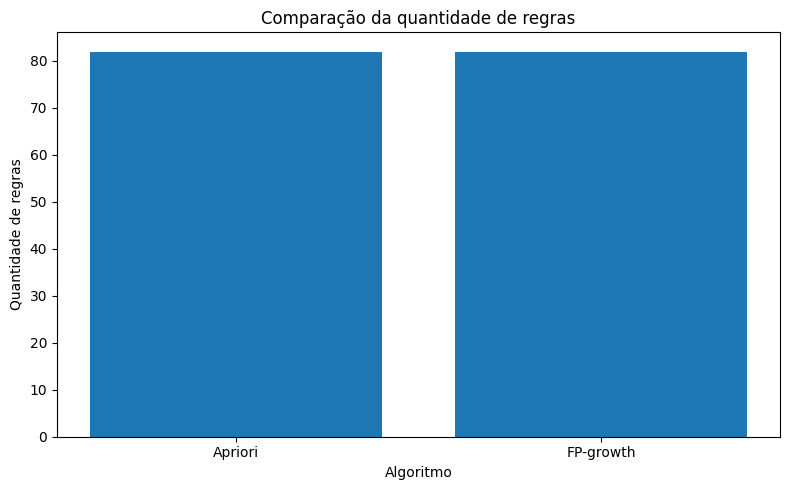

In [ ]:
plt.figure(figsize=(8, 5))
plt.bar(comparacao_algoritmos['Algoritmo'], comparacao_algoritmos['Quantidade_regras'])
plt.title('Comparação da quantidade de regras')
plt.xlabel('Algoritmo')
plt.ylabel('Quantidade de regras')
plt.tight_layout()
plt.show()

## 15. Interpretação das regras encontradas

Observe as principais regras e responda:
- quais eventos aparecem juntos com frequência;
- quais regras parecem úteis para manutenção ou monitoramento;
- que relações chamaram mais atenção.


In [ ]:
# Utilize a variável `top_regras_apriori` para acessar a tabela com as principais regras do Apriori.
# Selecione as colunas `regra`, `support`, `confidence` e `lift`.
# A coluna `regra` apresenta o antecedente e o consequente no formato "A -> B".
# A coluna `support` apresenta a frequência da regra em toda a base de dados.
# A coluna `confidence` apresenta a confiança da regra.
# A coluna `lift` apresenta a força da associação.
# Exiba o resultado para visualizar essas quatro informações das regras.

In [ ]:
top_regras_apriori[['regra', 'support', 'confidence', 'lift']]

,regra,support,confidence,lift
65,"alta_temperatura, valvula_desregulada -> erro_...",0.088462,0.696970,3.020202
41,"alta_pressao, valvula_desregulada -> erro_vaza...",0.092308,0.648649,2.810811
56,"alta_vibracao, leituras_invalidas_altas -> tem...",0.088462,0.741935,2.606800
39,"alta_pressao, erro_vazao_alto -> valvula_desre...",0.092308,0.705882,2.584921
30,"bomba_desgastada, tempo_resposta_lento -> alta...",0.100000,0.962963,2.554800
63,"bomba_desgastada, produto_Base -> alta_vibracao",0.088462,0.958333,2.542517
47,"alta_pressao, leituras_invalidas_altas -> temp...",0.092308,0.705882,2.480127
46,"alta_pressao, tempo_resposta_lento -> leituras...",0.092308,0.615385,2.461538
20,"alta_pressao, alta_vibracao -> bomba_desgastada",0.115385,0.652174,2.457467
13,"alta_vibracao, consumo_energia_alto -> bomba_d...",0.142308,0.649123,2.445970


**Interpretação do aluno:**  
-  
-  
-  

## 16. Comparação entre abordagens de modelagem

Preencha um quadro comparativo entre:
- associação;
- classificação;
- regressão;
- agrupamento.


In [ ]:
# Crie uma variável chamada `quadro_comparativo` para armazenar uma tabela
# comparando quatro abordagens de Machine Learning.

# Utilize `pd.DataFrame()` para criar o DataFrame.

# Crie a coluna `Abordagem` com os nomes das quatro abordagens:
# Associação, Classificação, Regressão e Agrupamento.

# Crie a coluna `Pergunta_típica` com a principal pergunta
# que cada abordagem procura responder.
# Para Associação, utilize: "Quais eventos tendem a ocorrer juntos?"
# Para Classificação, utilize: "Em qual classe este registro se encaixa?"
# Para Regressão, utilize: "Qual valor contínuo queremos estimar?"
# Para Agrupamento, utilize: "Quais grupos semelhantes existem na base?"

# Crie a coluna `Tipo_de_aprendizado` para informar se cada abordagem
# utiliza aprendizado supervisionado ou não supervisionado.
# Associação → "Não supervisionado"
# Classificação → "Supervisionado"
# Regressão → "Supervisionado"
# Agrupamento → "Não supervisionado"

# Crie a coluna `Exemplo_industrial` para apresentar um exemplo
# de aplicação de cada abordagem em um contexto industrial.
# Associação → "Combinação frequente de falhas e condições operacionais"
# Classificação → "Prever status de falha"
# Regressão → "Prever vazão, temperatura ou consumo"
# Agrupamento → "Identificar perfis operacionais"

# Ao final, a variável `quadro_comparativo` conterá uma tabela
# com quatro linhas, uma para cada abordagem de Machine Learning,
# e quatro colunas com suas principais características.

In [ ]:
quadro_comparativo = pd.DataFrame({
    'Abordagem': ['Associação', 'Classificação', 'Regressão', 'Agrupamento'],
    'Pergunta_típica': [
        'Quais eventos tendem a ocorrer juntos?',
        'Em qual classe este registro se encaixa?',
        'Qual valor contínuo queremos estimar?',
        'Quais grupos semelhantes existem na base?'
    ],
    'Tipo_de_aprendizado': [
        'Não supervisionado',
        'Supervisionado',
        'Supervisionado',
        'Não supervisionado'
    ],
    'Exemplo_industrial': [
        'Combinação frequente de falhas e condições operacionais',
        'Prever status de falha',
        'Prever vazão, temperatura ou consumo',
        'Identificar perfis operacionais'
    ]
})
quadro_comparativo

,Abordagem,Pergunta_típica,Tipo_de_aprendizado,Exemplo_industrial
0,Associação,Quais eventos tendem a ocorrer juntos?,Não supervisionado,Combinação frequente de falhas e condições ope...
1,Classificação,Em qual classe este registro se encaixa?,Supervisionado,Prever status de falha
2,Regressão,Qual valor contínuo queremos estimar?,Supervisionado,"Prever vazão, temperatura ou consumo"
3,Agrupamento,Quais grupos semelhantes existem na base?,Não supervisionado,Identificar perfis operacionais


## 17. Visualização sintética das abordagens

Gere um gráfico simples para representar as abordagens estudadas na aula.


In [ ]:
# Crie uma nova figura usando `plt.figure()` e defina o tamanho com `figsize=(10, 5)`.

# Crie um gráfico de barras usando `plt.bar()`.
# Utilize `quadro_comparativo['Abordagem']` como valores do eixo X.
# Utilize a lista `[1, 1, 1, 1]` como valores do eixo Y,
# representando a presença de cada abordagem no quadro comparativo.

# Defina o título do gráfico usando `plt.title()`.
# Título: 'Abordagens de modelagem estudadas na aula'.

# Defina o nome do eixo X usando `plt.xlabel()`.
# Nome do eixo X: 'Abordagem'.

# Defina o nome do eixo Y usando `plt.ylabel()`.
# Nome do eixo Y: 'Presença no quadro comparativo'.

# Utilize `plt.tight_layout()` para ajustar automaticamente o espaçamento dos elementos do gráfico.

# Utilize `plt.show()` para exibir o gráfico.

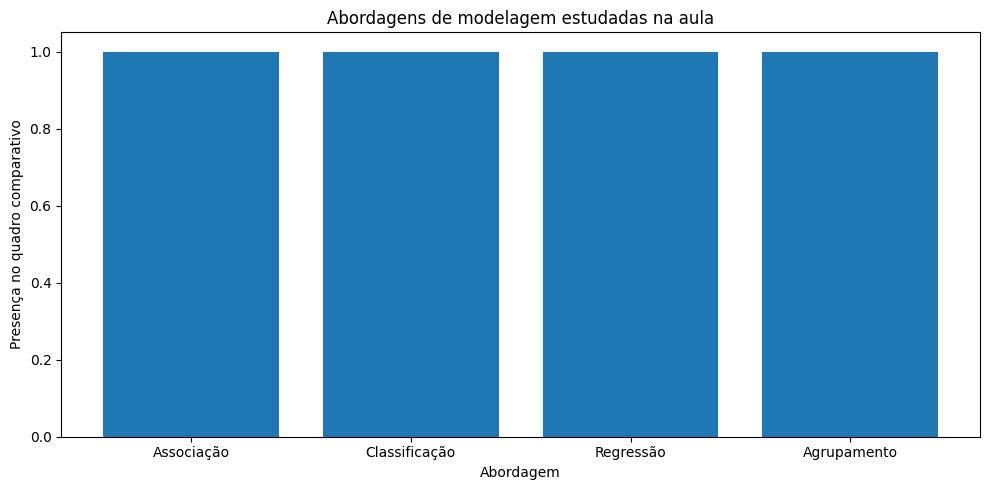

In [ ]:
plt.figure(figsize=(10, 5))
plt.bar(quadro_comparativo['Abordagem'], [1, 1, 1, 1])
plt.title('Abordagens de modelagem estudadas na aula')
plt.xlabel('Abordagem')
plt.ylabel('Presença no quadro comparativo')
plt.tight_layout()
plt.show()

## 18. Definição do problema e escolha da abordagem

Escreva:
- qual problema pode ser tratado por associação;
- quando seria melhor usar classificação;
- quando seria melhor usar regressão;
- quando o agrupamento faria mais sentido.


**Resposta do aluno:**  
- Associação:  
- Classificação:  
- Regressão:  
- Agrupamento:  


## 19. Exportação dos resultados

Salve:
1. um arquivo CSV com as regras encontradas;
2. um arquivo CSV com o quadro comparativo;
3. um arquivo CSV com a comparação entre Apriori e FP-growth.


In [ ]:
# Exporte as colunas `antecedents`, `consequents`, `support`, `confidence` e `lift`
# do DataFrame `regras_apriori` para um arquivo CSV.
# Utilize `to_csv()` para realizar a exportação.
# Defina o nome do arquivo como `regras_associacao_apriori_aula9_visual.csv`.
# Utilize `index=False` para não salvar o índice do DataFrame no arquivo CSV.

# Exporte o DataFrame `quadro_comparativo` para um arquivo CSV.
# Utilize `to_csv()` e defina o nome do arquivo como `quadro_comparativo_modelagem_aula9_visual.csv`.
# Utilize `index=False` para não salvar o índice do DataFrame no arquivo.

# Exporte o DataFrame `comparacao_algoritmos` para um arquivo CSV.
# Utilize `to_csv()` e defina o nome do arquivo como `comparacao_apriori_fpgrowth_aula9.csv`.
# Utilize `index=False` para não salvar o índice do DataFrame no arquivo.

# Exiba uma mensagem informando que os três arquivos foram exportados com sucesso.
# Utilize `print()` com a mensagem: 'Arquivos exportados com sucesso.'.

In [ ]:
regras_apriori[['antecedents', 'consequents', 'support', 'confidence', 'lift']].to_csv(
    'regras_associacao_apriori_aula9_visual.csv', index=False
)
quadro_comparativo.to_csv('quadro_comparativo_modelagem_aula9_visual.csv', index=False)
comparacao_algoritmos.to_csv('comparacao_apriori_fpgrowth_aula9.csv', index=False)
print('Arquivos exportados com sucesso.')

Arquivos exportados com sucesso.


## 20. Fechamento

Verifique se você:
- diferenciou corretamente as finalidades dos algoritmos estudados;
- comparou as abordagens com coerência técnica;
- selecionou modelos pertinentes ao caso industrial;
- registrou sua justificativa de forma organizada;
- apresentou os resultados de forma visual para facilitar a interpretação.


###***Espaço IA Generativa***
>Traga aqui os trechos da aula [005] ou [006] para consultar a IA e te ajudar a compreender as questões